# Audit figures

Regenerates every figure and the results table in `docs/figures/` from scratch. The run is deterministic and offline: a seeded synthetic ledger (seed 42) is generated, audited month by month into a temporary DuckDB file, and the figures are drawn from that run. Execute with `make figures`.

**Caveat for every figure:** all results come from synthetic data with injected anomalies whose labels are known. They show how the method behaves on this generator, not how it performs on a real ledger. Thresholds, weights and parameters are assumptions, not validated limits.

In [1]:
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from continuous_audit_lab.data.schema import LABEL_COLUMN, TXN_ID_COLUMN
from continuous_audit_lab.data.synthetic import ROUND_AMOUNT, generate
from continuous_audit_lab.monitor.kri import KRI_NAMES
from continuous_audit_lab.monitor.runner import run_months
from continuous_audit_lab.scoring.evaluate import (
    AMOUNT_RANKER,
    DEFAULT_K,
    DEFAULT_WARMUP_MONTHS,
    RANDOM_BASELINE_SEED,
    RANDOM_RANKER,
    RISK_RANKER,
    evaluate_synthetic,
    format_results_table,
    recall_at_k,
    summarise,
)
from continuous_audit_lab.scoring.risk import score_month
from continuous_audit_lab.scoring.rules import DATE_COLUMN
from continuous_audit_lab.scoring.stats import month_start

SEED = 42
K_VALUES = list(range(10, 201, 10))
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
payments = generate(seed=SEED)
work_dir = tempfile.TemporaryDirectory()
db_path = Path(work_dir.name) / "audit.duckdb"
run_summary = run_months(payments, out_path=str(db_path), source="synthetic")
run_summary = {key: run_summary[key] for key in ("run_id", "months", "alerts")}
run_summary

{'run_id': 'run-9636d177763f', 'months': 36, 'alerts': 1750}

## 1. KRI trends

`kri_trends.png` shows the seven monthly key risk indicators as the monitor computed them from the audit tests. Dashed amber and red lines are the limits set from the first 12 months, and the shaded area marks those baseline months, which set the limits and are not a judgement. The limits are assumptions calibrated on the synthetic baseline. A spike here is a prompt to look at the payments, not evidence of fraud.

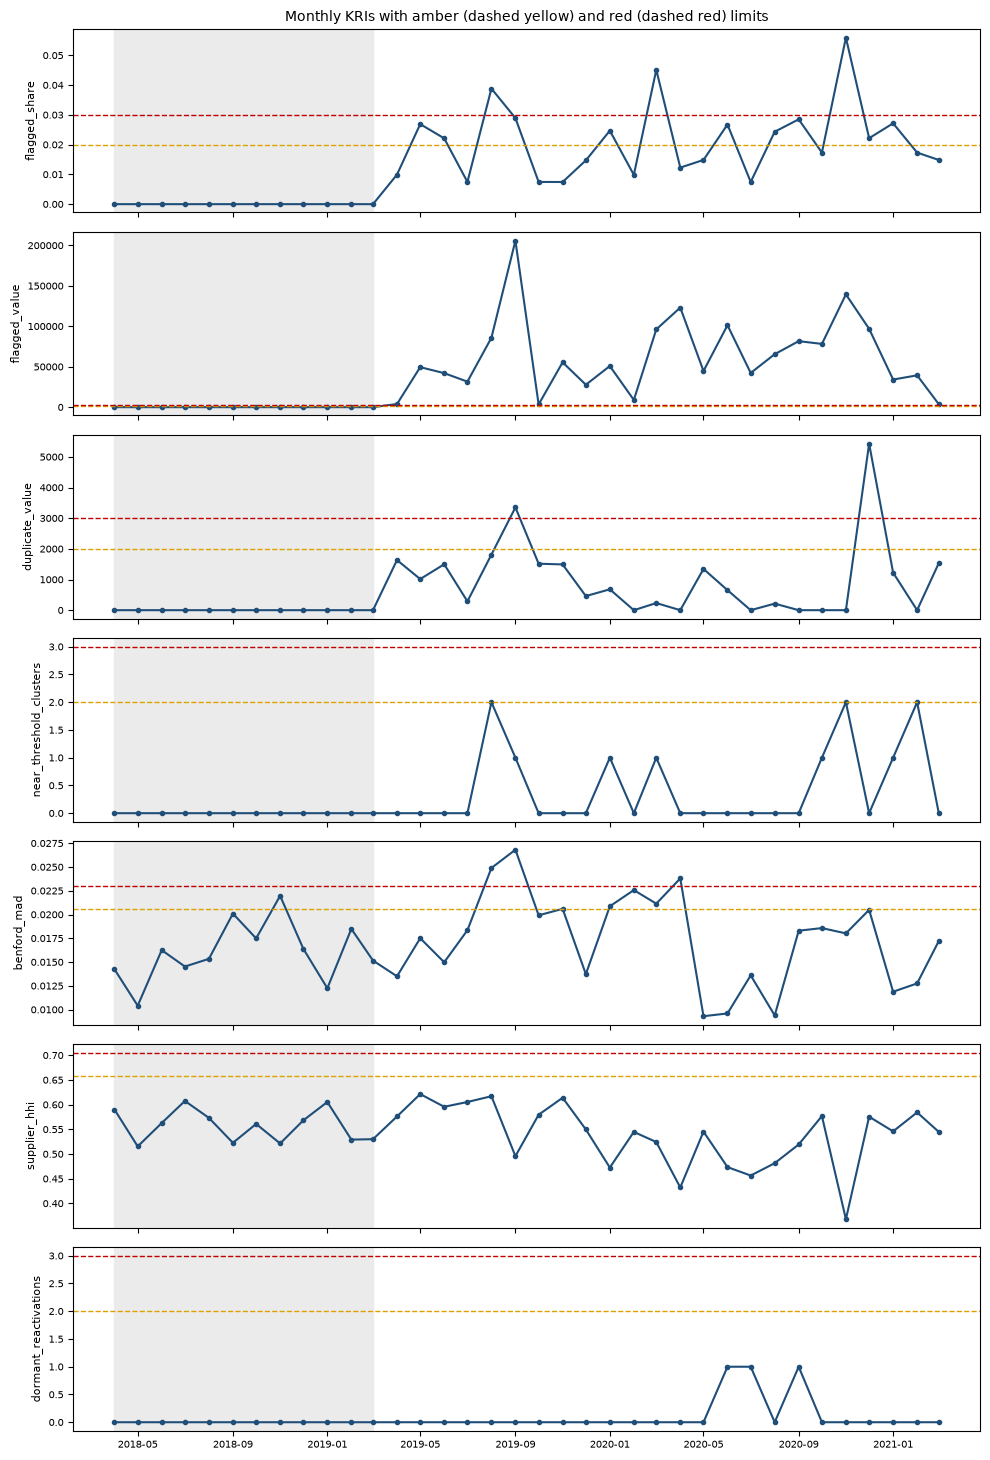

In [3]:
with duckdb.connect(str(db_path), read_only=True) as connection:
    kris = connection.execute("SELECT * FROM kris ORDER BY period").df()
    thresholds = connection.execute("SELECT * FROM kri_thresholds").df().set_index("kri")
kris["period"] = pd.to_datetime(kris["period"])
baseline_end = kris["period"].iloc[DEFAULT_WARMUP_MONTHS - 1]
figure, axes = plt.subplots(len(KRI_NAMES), 1, figsize=(10, 2.1 * len(KRI_NAMES)), sharex=True)
for axis, name in zip(axes, KRI_NAMES):
    axis.axvspan(kris["period"].iloc[0], baseline_end, color="0.92", zorder=0)
    axis.plot(kris["period"], kris[name], marker="o", markersize=3, color="#1f4e79")
    axis.axhline(thresholds.at[name, "amber"], color="#e0a100", linestyle="--", linewidth=1)
    axis.axhline(thresholds.at[name, "red"], color="#c00000", linestyle="--", linewidth=1)
    axis.set_ylabel(name, fontsize=8)
    axis.tick_params(labelsize=7)
axes[0].set_title("Monthly KRIs with amber (dashed yellow) and red (dashed red) limits", fontsize=10)
figure.tight_layout()
figure.savefig(FIGURES / "kri_trends.png", dpi=120)
plt.show()

## 2. Recall@k against the labels

`recall_at_k.png` compares the risk score with two baselines, ranking by amount alone and by a seeded random order, over the months after the 12-month warm-up. Recall@k is the share of that month's labelled anomalies found in the top k, and the curve is the mean over months that contain at least one anomaly. The labels are the synthetic injections, so this measures recovery of injected patterns, not real fraud detection.

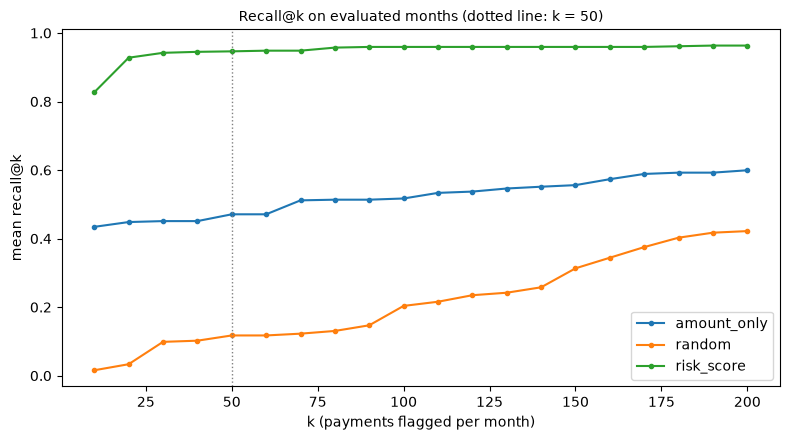

In [4]:
def ranked_flags(
    month_frame: pd.DataFrame,
    scores: pd.DataFrame,
    labels: pd.Series,
    rng: np.random.Generator,
) -> dict[str, list[bool]]:
    ids = month_frame[TXN_ID_COLUMN].to_numpy()
    by_amount = month_frame.sort_values(["amount", TXN_ID_COLUMN], ascending=[False, True])
    return {
        RISK_RANKER: labels.loc[scores.index.to_numpy()].tolist(),
        AMOUNT_RANKER: labels.loc[by_amount[TXN_ID_COLUMN].to_numpy()].tolist(),
        RANDOM_RANKER: labels.loc[rng.permutation(ids)].tolist(),
    }


def recall_curves(payments: pd.DataFrame, k_values: list[int], warmup_months: int) -> pd.DataFrame:
    labels = payments.set_index(TXN_ID_COLUMN)[LABEL_COLUMN].fillna("").ne("")
    months_of = payments[DATE_COLUMN].map(month_start)
    rng = np.random.default_rng(RANDOM_BASELINE_SEED)
    records = []
    for month in months_of.drop_duplicates().sort_values().iloc[warmup_months:]:
        month_frame = payments[months_of == month]
        anomalies = int(labels.loc[month_frame[TXN_ID_COLUMN].to_numpy()].sum())
        scores = score_month(payments, month)
        for ranker, flags in ranked_flags(month_frame, scores, labels, rng).items():
            for k in k_values:
                records.append(
                    {"ranker": ranker, "k": k, "recall": recall_at_k(flags, k, anomalies)}
                )
    return pd.DataFrame(records).groupby(["ranker", "k"])["recall"].mean().reset_index()


recall_by_k = recall_curves(payments, K_VALUES, DEFAULT_WARMUP_MONTHS)
figure, axis = plt.subplots(figsize=(8, 4.5))
for ranker, group in recall_by_k.groupby("ranker"):
    axis.plot(group["k"], group["recall"], marker="o", markersize=3, label=ranker)
axis.axvline(DEFAULT_K, color="0.5", linestyle=":", linewidth=1)
axis.set_xlabel("k (payments flagged per month)")
axis.set_ylabel("mean recall@k")
axis.set_title("Recall@k on evaluated months (dotted line: k = 50)", fontsize=10)
axis.legend()
figure.tight_layout()
figure.savefig(FIGURES / "recall_at_k.png", dpi=120)
plt.show()

## 3. Benford first digits

`benford.png` compares the observed first-digit share with Benford's expected share, for one month with no injected anomalies and for the month with the most injected round amounts. The MAD in each title is the mean absolute deviation over digits 1 to 9, the same measure the Benford SQL test reports. A few injected round amounts barely move a month of about 400 payments, so the right panel is illustrative. Lognormal amounts are not expected to follow Benford's law exactly, so the clean month is a reference point, not proof of conformity.

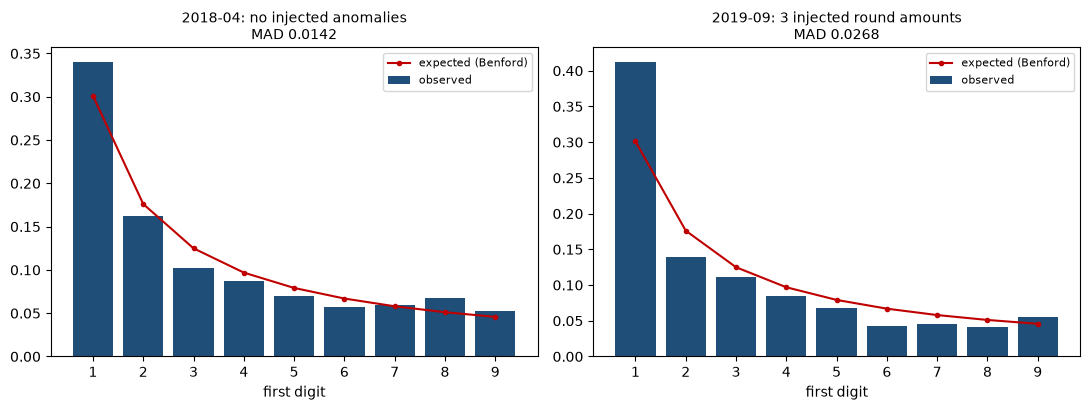

In [5]:
def first_digit_shares(amounts: pd.Series) -> np.ndarray:
    positive = amounts[amounts > 0].to_numpy(dtype=float)
    leading = np.floor(positive / np.power(10.0, np.floor(np.log10(positive)))).astype(int)
    counts = np.bincount(leading, minlength=10)[1:10]
    return counts / counts.sum()


def benford_expected() -> np.ndarray:
    return np.log10(1 + 1 / np.arange(1, 10))


def benford_mad(shares: np.ndarray, expected: np.ndarray) -> float:
    return float(np.mean(np.abs(shares - expected)))


def plot_first_digits(axis: plt.Axes, amounts: pd.Series, title: str) -> None:
    digits = np.arange(1, 10)
    expected = benford_expected()
    shares = first_digit_shares(amounts)
    axis.bar(digits, shares, color="#1f4e79", label="observed")
    axis.plot(digits, expected, color="#c00000", marker="o", markersize=3, label="expected (Benford)")
    axis.set_title(f"{title}\nMAD {benford_mad(shares, expected):.4f}", fontsize=10)
    axis.set_xlabel("first digit")
    axis.set_xticks(digits)
    axis.legend(fontsize=8)


months_of = payments[DATE_COLUMN].map(month_start)
anomalous_months = set(months_of[payments[LABEL_COLUMN].fillna("").ne("")])
clean_month = next(
    month for month in months_of.drop_duplicates().sort_values() if month not in anomalous_months
)
round_months = months_of[payments[LABEL_COLUMN] == ROUND_AMOUNT]
round_counts = round_months.value_counts().sort_index()
round_month = round_counts.idxmax()
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
plot_first_digits(
    axes[0],
    payments.loc[months_of == clean_month, "amount"],
    f"{clean_month:%Y-%m}: no injected anomalies",
)
plot_first_digits(
    axes[1],
    payments.loc[months_of == round_month, "amount"],
    f"{round_month:%Y-%m}: {int(round_counts[round_month])} injected round amounts",
)
figure.tight_layout()
figure.savefig(FIGURES / "benford.png", dpi=120)
plt.show()

## 4. Alerts by rule

`alerts_by_test.png` counts each month's alerts, the top 50 positively scored payments, by the rules that fired on them. An alert that fired several rules is counted once under each rule, so bar heights can exceed the number of alerts. Alerts with no rule fired are ranked on the statistical terms alone and appear as 'no rule fired'. Synthetic data only.

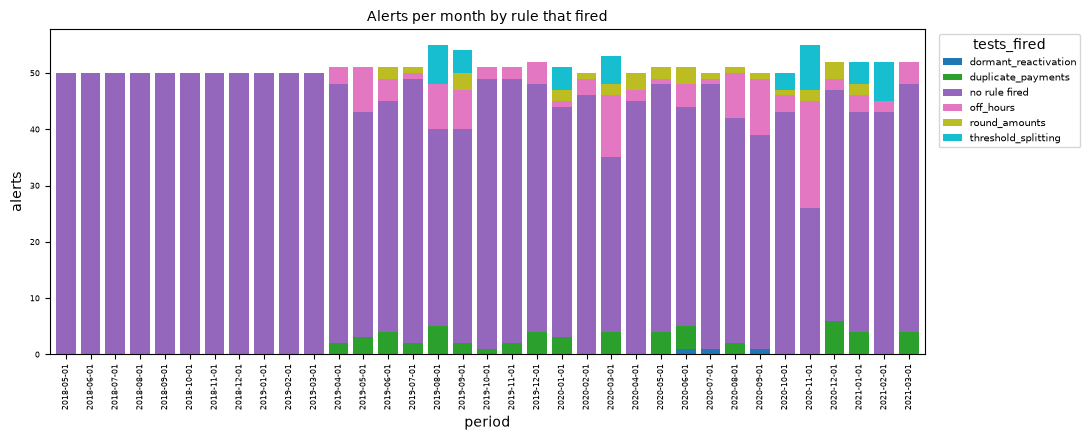

In [6]:
import json

with duckdb.connect(str(db_path), read_only=True) as connection:
    alerts = connection.execute("SELECT period, tests_fired FROM alerts").df()
fired = pd.DataFrame(
    {"period": alerts["period"], "test": alerts["tests_fired"].map(json.loads)}
)
fired["test"] = fired["test"].map(lambda tests: tests or ["no rule fired"])
alert_counts = fired.explode("test").groupby(["period", "test"]).size().unstack(fill_value=0)
figure, axis = plt.subplots(figsize=(11, 4.5))
alert_counts.plot(kind="bar", stacked=True, ax=axis, colormap="tab10", width=0.8)
axis.set_xlabel("period")
axis.set_ylabel("alerts")
axis.tick_params(labelsize=6)
axis.set_title("Alerts per month by rule that fired", fontsize=10)
axis.legend(title="tests_fired", fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
figure.tight_layout()
figure.savefig(FIGURES / "alerts_by_test.png", dpi=120)
plt.show()

## 5. Results table

`results_table.md` is the precision@50 and recall@50 summary for the three rankers over the evaluated months, produced by `evaluate_synthetic` and `summarise` and written as markdown rather than an image. The numbers are measured against synthetic labels only.

In [7]:
evaluated = evaluate_synthetic(payments, k=DEFAULT_K)
table = format_results_table(summarise(evaluated))
results_text = (
    f"Synthetic backtest, k = {DEFAULT_K}, evaluated months: {evaluated['month'].nunique()}\n\n"
    f"{table}\n"
)
(FIGURES / "results_table.md").write_text(results_text)
work_dir.cleanup()
print(results_text)

Synthetic backtest, k = 50, evaluated months: 24

| ranker | mean_precision_at_k | mean_recall_at_k | months | months_with_anomalies |
|---|---|---|---|---|
| risk_score | 0.153 | 0.946 | 24.000 | 24.000 |
| amount_only | 0.077 | 0.471 | 24.000 | 24.000 |
| random | 0.021 | 0.117 | 24.000 | 24.000 |

